# Transformers, Self-Attention, BERT, GPT

In [ ]:
#!pip install transformers torch datasets sentencepiece accelerate

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModel,
    AutoModelForMaskedLM,
    AutoModelForSequenceClassification,
    AutoModelForCausalLM
)

## Self-Attention: The Core Idea

### Multi-Head Attention (Why many heads?)

Visualize self-attention using PyTorch

In [ ]:
import torch
import torch.nn.functional as F

# Dummy sequence of 5 tokens, embedding dim = 4
x = torch.randn(5, 4)

Wq = torch.randn(4, 4)
Wk = torch.randn(4, 4)
Wv = torch.randn(4, 4)

Q = x @ Wq
K = x @ Wk
V = x @ Wv

scores = (Q @ K.T) / (4 ** 0.5)   # scaled dot-product attention
attn = F.softmax(scores, dim=-1)

context_vector = attn @ V

attn, context_vector

### Transformer Architecture (Encoder/Decoder)

BERT Explained (Encoder Only)

In [ ]:
from transformers import pipeline
bert = pipeline("fill-mask", model="bert-base-uncased")
bert("Paris is the [MASK] of France.")

### GPT Explained (Decoder Only)

In [ ]:
from transformers import pipeline
gpt = pipeline("text-generation", model="gpt2")
gpt("Once upon a time in Bangalore,")[0]["generated_text"]

#### BERT vs GPT (Simple Table)

#### Self-Attention is Parallel → Fast on GPUs

In [ ]:
def positional_encoding(seq_len, d_model):
    PE = torch.zeros(seq_len, d_model)
    pos = torch.arange(0, seq_len).unsqueeze(1).float()  # shape [seq_len, 1]

    for i in range(0, d_model, 2):
        div_term = 10000 ** (i / d_model)
        PE[:, i] = torch.sin(pos.squeeze(1) / div_term)  # shape [seq_len]
        PE[:, i+1] = torch.cos(pos.squeeze(1) / div_term)
    return PE

PE = positional_encoding(50, 16)

plt.figure(figsize=(8,4))
sns.heatmap(PE.numpy(), cmap="viridis")
plt.title("Positional Encoding Pattern")
plt.show()

Full Transformer Block Diagram

Mini Transformer Attention Visualization (HF)

In [ ]:
from transformers import AutoModel, AutoTokenizer
import torch

model = AutoModel.from_pretrained("bert-base-uncased", output_attentions=True)
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

inputs = tokenizer("Hello I am learning transformers!", return_tensors="pt")
outputs = model(**inputs)

attn = outputs.attentions  
len(attn), attn[0].shape   # (layers, batch, heads, tokens, tokens)

In [ ]:
attn

In [ ]:
#!pip install tf-keras

In [ ]:
from transformers import pipeline

fill = pipeline("fill-mask", model="bert-base-uncased")
fill("The capital of France is [MASK].")

In [ ]:
clf = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")

clf("this movie was so bad i would watch it again")

BERT Sentence Embeddings (Used in RAG, LangChain)

In [17]:
tok = AutoTokenizer.from_pretrained("bert-base-uncased")
model = AutoModel.from_pretrained("bert-base-uncased")

text = "Transformers changed deep learning forever"
tokens = tok(text, return_tensors="pt")

with torch.no_grad():
    output = model(**tokens).last_hidden_state
    embedding = output.mean(dim=1)

embedding.shape

torch.Size([1, 768])

In [18]:
tokens

{'input_ids': tensor([[  101, 19081,  2904,  2784,  4083,  5091,   102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1]])}

In [15]:
embedding

tensor([[ 4.8118e-01,  2.2255e-02,  2.3437e-01,  2.9283e-01,  1.5477e-01,
         -3.5160e-01,  3.6276e-01,  6.6813e-01,  2.6318e-01, -6.2313e-01,
          3.3251e-01, -1.2680e-01,  4.0204e-02,  4.2963e-01, -8.1283e-02,
          9.4664e-03, -9.2769e-03, -2.1423e-01,  1.2391e-01,  2.1578e-01,
         -5.5755e-02,  4.9718e-02, -1.1202e-02,  7.2107e-01,  2.4249e-01,
         -7.8887e-02, -1.3534e-01, -4.6789e-02, -2.8825e-01, -2.0091e-01,
         -4.5834e-02, -1.0742e-01, -1.5397e-02, -2.3608e-01, -2.8766e-01,
         -7.1730e-02, -1.3620e-01, -2.9062e-01, -2.6933e-01, -5.8896e-02,
         -5.6685e-01, -7.8516e-02,  6.8911e-02,  1.5713e-03, -1.7109e-01,
          3.9922e-04, -2.2543e-01, -8.7175e-02,  1.0485e-01, -1.0569e-01,
         -1.3154e-01, -4.8225e-02,  1.5725e-01,  1.5575e-01, -8.4316e-02,
          4.2958e-01,  1.1856e-01, -2.9336e-01, -1.3419e-01,  1.0632e-01,
          2.0947e-01,  4.6667e-01, -2.2501e-01, -1.9839e-01,  1.0379e-01,
          3.3701e-01, -4.6396e-01,  5.

BERT Attention Heatmap

In [21]:
inputs

{'input_ids': tensor([[  101,  4937,  2938,  2006,  1996, 13523,   102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1]])}

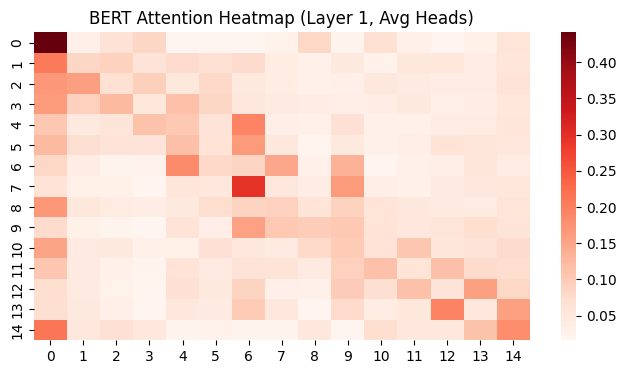

In [22]:
model = AutoModel.from_pretrained("bert-base-uncased", output_attentions=True)
tok = AutoTokenizer.from_pretrained("bert-base-uncased")

inputs = tok("he and the dog were walking down the street and it ran away", return_tensors="pt")
outputs = model(**inputs)

attn = outputs.attentions[0][0]   # 1st layer, 1st batch = (heads, tokens, tokens)

plt.figure(figsize=(8,4))
sns.heatmap(attn.mean(0).detach().numpy(), cmap="Reds")
plt.title("BERT Attention Heatmap (Layer 1, Avg Heads)")
plt.show()

In [ ]:
gen = pipeline("text-generation", model="gpt2", max_length=60)
gen("Once upon a time in Bangalore")[0]["generated_text"]

In [ ]:
print("\n--- BERT (Understanding) ---")
print(fill("The weather today is very [MASK]."))

print("\n--- GPT (Generation) ---")
print(gen("The weather today is very")[0]["generated_text"])

How Transformers Power Agentic AI